# La matemática de las capas y las activaciones

Segundo notebook del módulo. Cubre las piezas con las que se arma un modelo: `nn.Linear`, su inicialización, y las activaciones `ReLU`, `Sigmoid`, `Tanh` y `Softmax`. Para cada una: la fórmula, de dónde sale, y una versión a mano comprobada contra PyTorch.

**Contenido**

1. `nn.Linear`: una transformación afín
2. Cómo inicializa PyTorch los pesos
3. Por qué la escala de la inicialización importa
4. `ReLU`
5. `Sigmoid`
6. `Tanh`
7. Las tres activaciones y sus derivadas
8. Gradientes que se desvanecen
9. `Softmax`
10. Estabilidad numérica: `logsumexp` y `log_softmax`
11. Resumen y ejercicios

In [1]:
import math

import torch
from torch import nn
from torch.autograd.functional import jacobian
import matplotlib.pyplot as plt

torch.manual_seed(0)
torch.set_default_dtype(torch.float64)
print("Versión de PyTorch:", torch.__version__)

Versión de PyTorch: 2.11.0+cpu


## 1. `nn.Linear`: una transformación afín

`nn.Linear(n, m)` implementa la función

$$y = W x + b \qquad W \in \mathbb{R}^{m \times n}, \quad b \in \mathbb{R}^m$$

que recibe un vector de $n$ entradas y devuelve uno de $m$ salidas. Cada fila de $W$ es una neurona: la salida $i$ es el producto punto de la fila $i$ con la entrada, más el sesgo $b_i$.

El nombre es engañoso. En matemática, toda función *lineal* cumple $f(0) = 0$, y esta no lo hace cuando el sesgo es distinto de cero. El término correcto es transformación **afín**: una lineal más un desplazamiento.

**La convención de formas.** PyTorch procesa lotes con un ejemplo por **fila**. Si $X$ tiene forma `[N, n]`, aplicar $W$ a cada fila equivale a multiplicar por la traspuesta desde la derecha:

$$Y = X W^\top + b$$

con $Y$ de forma `[N, m]`. El sesgo se suma a cada fila por broadcasting. Por eso `capa.weight` tiene forma `[salidas, entradas]`, al revés del orden en que se escriben los argumentos.

In [2]:
capa = nn.Linear(in_features=3, out_features=2)
X = torch.randn(5, 3)                               # 5 ejemplos, 3 características

a_mano = X @ capa.weight.T + capa.bias

print("forma de weight:", tuple(capa.weight.shape), "  forma de bias:", tuple(capa.bias.shape))
print("forma de la salida:", tuple(capa(X).shape))
print("¿X Wᵀ + b coincide con capa(X)?", torch.allclose(a_mano, capa(X)))

forma de weight: (2, 3)   forma de bias: (2,)
forma de la salida: (5, 2)
¿X Wᵀ + b coincide con capa(X)? True


La cantidad de parámetros es $m \cdot n$ pesos más $m$ sesgos. Los gradientes de esta capa son los del producto matricial, deducidos en el notebook anterior: si $\delta$ es el gradiente respecto de la salida,

$$\frac{\partial L}{\partial W} = \delta^\top X \qquad \frac{\partial L}{\partial b} = \sum_{\text{filas}} \delta \qquad \frac{\partial L}{\partial X} = \delta \, W$$

## 2. Cómo inicializa PyTorch los pesos

Los pesos de una capa oculta no pueden partir todos iguales (por ejemplo, en cero): todas sus neuronas calcularían lo mismo, recibirían el mismo gradiente y seguirían siendo idénticas para siempre. Hay que **romper la simetría** con valores aleatorios.

`nn.Linear` sortea pesos y sesgos de una distribución uniforme cuyo ancho depende de la cantidad de entradas $n$ (llamada `fan_in`):

$$W_{ij}, \; b_i \sim \mathcal{U}\left( -\frac{1}{\sqrt{n}}, \; \frac{1}{\sqrt{n}} \right)$$

La varianza de una uniforme en $(-a, a)$ es $a^2 / 3$, así que

$$\text{Var}(W_{ij}) = \frac{1}{3n}$$

Lo comprobamos con una capa grande, para tener muchas muestras:

In [3]:
n = 1000
capa = nn.Linear(n, n)
W = capa.weight.detach()

print(f"límite teórico 1/√n      : {1 / math.sqrt(n):.5f}")
print(f"mínimo y máximo de W     : {W.min():.5f}, {W.max():.5f}")
print(f"varianza teórica 1/(3n)  : {1 / (3 * n):.3e}")
print(f"varianza medida de W     : {W.var():.3e}")
print(f"mínimo y máximo del sesgo: {capa.bias.min():.5f}, {capa.bias.max():.5f}")

límite teórico 1/√n      : 0.03162
mínimo y máximo de W     : -0.03162, 0.03162
varianza teórica 1/(3n)  : 3.333e-04
varianza medida de W     : 3.336e-04
mínimo y máximo del sesgo: -0.03161, 0.03145


## 3. Por qué la escala de la inicialización importa

¿Por qué dividir por $\sqrt{n}$? La respuesta sale de calcular la varianza de lo que produce una neurona.

Sea $z = \sum_{j=1}^{n} w_j x_j$, con pesos independientes entre sí y de las entradas, y de media cero. Entonces $z$ tiene media cero y

$$\text{Var}(z) = \sum_{j=1}^{n} \text{Var}(w_j x_j) = n \cdot \text{Var}(w) \cdot \mathbb{E}[x^2]$$

La varianza de la salida crece con la cantidad de entradas. Si $\text{Var}(w)$ no dependiera de $n$, una capa de 1000 entradas produciría valores unas 30 veces mayores que los que recibe, y tras varias capas los números explotarían. Elegir $\text{Var}(w) \propto 1/n$ cancela ese factor.

Falta ver qué constante conviene. Depende de la activación. Con ReLU, la salida de la capa es $h = \max(0, z)$. Si los pesos se sortean de una distribución simétrica, $z$ también es simétrica en torno a cero: la mitad de las veces la ReLU la anula y la otra mitad la deja igual:

$$\mathbb{E}[h^2] = \frac{1}{2} \, \mathbb{E}[z^2] = \frac{1}{2} \text{Var}(z)$$

Juntando ambas ecuaciones, la magnitud de las activaciones cambia de una capa a la siguiente según

$$\mathbb{E}[h_{\ell}^2] = \frac{1}{2} \, n \, \text{Var}(w) \; \mathbb{E}[h_{\ell-1}^2]$$

Para que se mantenga constante a lo largo de la red hace falta que el factor valga 1:

$$\text{Var}(w) = \frac{2}{n}$$

Esta es la **inicialización de He** (o de Kaiming), disponible como `nn.init.kaiming_normal_`. Con la inicialización por omisión de `nn.Linear`, en cambio, $\text{Var}(w) = 1/(3n)$ y el factor es $\frac{1}{2} \cdot \frac{1}{3} = \frac{1}{6}$: el valor medio de $h^2$ se divide por seis en cada capa.

Verificamos las dos predicciones con una pila de 10 capas con ReLU y sin sesgo:

In [4]:
def magnitud_por_capa(inicializar, capas=10, ancho=512):
    """Devuelve E[h²] a la salida de cada capa de una pila Linear + ReLU."""
    h = torch.randn(2000, ancho)                # entrada con E[x²] = 1
    magnitudes = []
    with torch.no_grad():
        for _ in range(capas):
            capa = nn.Linear(ancho, ancho, bias=False)
            inicializar(capa.weight)
            h = torch.relu(capa(h))
            magnitudes.append((h ** 2).mean().item())
    return magnitudes


por_omision = magnitud_por_capa(lambda w: None)                                     # no se toca
he = magnitud_por_capa(lambda w: nn.init.kaiming_normal_(w, nonlinearity="relu"))  # Var(w) = 2/n

print("capa   por omisión   teoría (1/6)^capa        He")
for i, (a, b) in enumerate(zip(por_omision, he), start=1):
    print(f"{i:3d}    {a:10.3e}    {(1 / 6) ** i:10.3e}      {b:8.3f}")

capa   por omisión   teoría (1/6)^capa        He
  1     1.660e-01     1.667e-01         0.997
  2     2.728e-02     2.778e-02         1.024
  3     4.622e-03     4.630e-03         0.958
  4     7.822e-04     7.716e-04         0.960
  5     1.409e-04     1.286e-04         0.992
  6     2.354e-05     2.143e-05         0.914
  7     4.837e-06     3.572e-06         0.906
  8     8.521e-07     5.954e-07         0.876
  9     1.419e-07     9.923e-08         0.763
 10     2.314e-08     1.654e-08         0.868


Las activaciones con la inicialización por omisión siguen de cerca la predicción $(1/6)^{\ell}$ y tras 10 capas son del orden de $10^{-8}$. Con He se mantienen cerca de 1. Las desviaciones respecto de la teoría vienen de que el ancho de las capas es finito y se van acumulando de una capa a la siguiente.

Cuando las activaciones se achican así, los gradientes también lo hacen y las primeras capas casi no aprenden. En redes de pocas capas, como las de este curso, la inicialización por omisión funciona bien. En redes profundas con ReLU conviene usar He explícitamente (o capas de normalización, que resuelven el problema de otra manera).

## 4. `ReLU`

$$\text{ReLU}(z) = \max(0, z) \qquad\qquad \text{ReLU}'(z) = \begin{cases} 1 & z > 0 \\ 0 & z < 0 \end{cases}$$

En $z = 0$ la función tiene una esquina y la derivada no existe. PyTorch usa el valor 0 ahí. Cualquier valor entre 0 y 1 sería una elección válida (se llama *subgradiente*), y en la práctica la elección tiene poco efecto.

Sus ventajas: es muy barata de calcular y su derivada vale exactamente 1 en toda la zona activa, por lo que no atenúa el gradiente. Su riesgo: una neurona cuya entrada es negativa para todos los datos tiene gradiente cero y deja de aprender (una *neurona muerta*).

Definimos una función auxiliar que obtiene la derivada de cualquier activación con autograd, para comparar con las fórmulas.

In [5]:
def derivada_con_autograd(funcion, z):
    z = z.clone().requires_grad_(True)
    return torch.autograd.grad(funcion(z).sum(), z)[0]      # la suma permite derivar todos los puntos a la vez


z = torch.linspace(-5, 5, 201)          # incluye exactamente el 0

relu_a_mano = torch.clamp(z, min=0)
relu_derivada = (z > 0).to(z.dtype)

print("ReLU     ¿valor coincide?   ", torch.allclose(relu_a_mano, torch.relu(z)))
print("ReLU     ¿derivada coincide?", torch.allclose(relu_derivada, derivada_con_autograd(torch.relu, z)))
print("Derivada de ReLU en z = 0 según PyTorch:", derivada_con_autograd(torch.relu, torch.tensor([0.0])).item())

ReLU     ¿valor coincide?    True
ReLU     ¿derivada coincide? True
Derivada de ReLU en z = 0 según PyTorch: 0.0


## 5. `Sigmoid`

$$\sigma(z) = \frac{1}{1 + e^{-z}}$$

Lleva cualquier número real al intervalo $(0, 1)$, por lo que su salida se interpreta como una probabilidad. Dos propiedades útiles:

**Simetría.** $\sigma(-z) = 1 - \sigma(z)$. Si $\sigma(z)$ es la probabilidad de una clase, $\sigma(-z)$ es la de la otra.

**Derivada.** Se puede escribir en términos de la propia función. Derivando con la regla de la cadena:

$$\sigma'(z) = \frac{e^{-z}}{(1 + e^{-z})^2} = \frac{1}{1 + e^{-z}} \cdot \frac{e^{-z}}{1 + e^{-z}} = \sigma(z) \, (1 - \sigma(z))$$

El último paso usa que $\dfrac{e^{-z}}{1 + e^{-z}} = 1 - \dfrac{1}{1 + e^{-z}}$.

El producto $\sigma (1 - \sigma)$ es máximo cuando $\sigma = 1/2$, es decir en $z = 0$, donde vale $1/4$. La derivada de la sigmoide **nunca supera 0.25**, y lejos de cero es prácticamente nula (la función se *satura*).

In [6]:
sigmoide_a_mano = 1 / (1 + torch.exp(-z))
sigmoide_derivada = sigmoide_a_mano * (1 - sigmoide_a_mano)

print("Sigmoide ¿valor coincide?   ", torch.allclose(sigmoide_a_mano, torch.sigmoid(z)))
print("Sigmoide ¿derivada coincide?", torch.allclose(sigmoide_derivada, derivada_con_autograd(torch.sigmoid, z)))
print("Sigmoide ¿σ(-z) = 1 - σ(z)? ", torch.allclose(torch.sigmoid(-z), 1 - torch.sigmoid(z)))
print("Valor máximo de la derivada :", sigmoide_derivada.max().item())

Sigmoide ¿valor coincide?    True
Sigmoide ¿derivada coincide? True
Sigmoide ¿σ(-z) = 1 - σ(z)?  True
Valor máximo de la derivada : 0.25


## 6. `Tanh`

$$\tanh(z) = \frac{e^{z} - e^{-z}}{e^{z} + e^{-z}} \qquad\qquad \tanh'(z) = 1 - \tanh^2(z)$$

Tiene la misma forma de S que la sigmoide, pero su salida está en $(-1, 1)$ y **centrada en cero**. De hecho es una sigmoide estirada y desplazada:

$$\tanh(z) = 2 \, \sigma(2z) - 1$$

Se comprueba multiplicando numerador y denominador de $\tanh$ por $e^{-z}$: queda $\dfrac{1 - e^{-2z}}{1 + e^{-2z}} = \dfrac{2}{1 + e^{-2z}} - 1$.

Su derivada máxima es 1 (en $z = 0$), cuatro veces la de la sigmoide. Que la salida esté centrada en cero también ayuda: las entradas de la capa siguiente no tienen todas el mismo signo. Por eso, entre las dos, se prefiere $\tanh$ para capas ocultas.

In [7]:
tanh_a_mano = (torch.exp(z) - torch.exp(-z)) / (torch.exp(z) + torch.exp(-z))
tanh_derivada = 1 - tanh_a_mano ** 2

print("Tanh     ¿valor coincide?      ", torch.allclose(tanh_a_mano, torch.tanh(z)))
print("Tanh     ¿derivada coincide?   ", torch.allclose(tanh_derivada, derivada_con_autograd(torch.tanh, z)))
print("Tanh     ¿tanh(z) = 2σ(2z) - 1?", torch.allclose(torch.tanh(z), 2 * torch.sigmoid(2 * z) - 1))

Tanh     ¿valor coincide?       True
Tanh     ¿derivada coincide?    True
Tanh     ¿tanh(z) = 2σ(2z) - 1? True


## 7. Las tres activaciones y sus derivadas

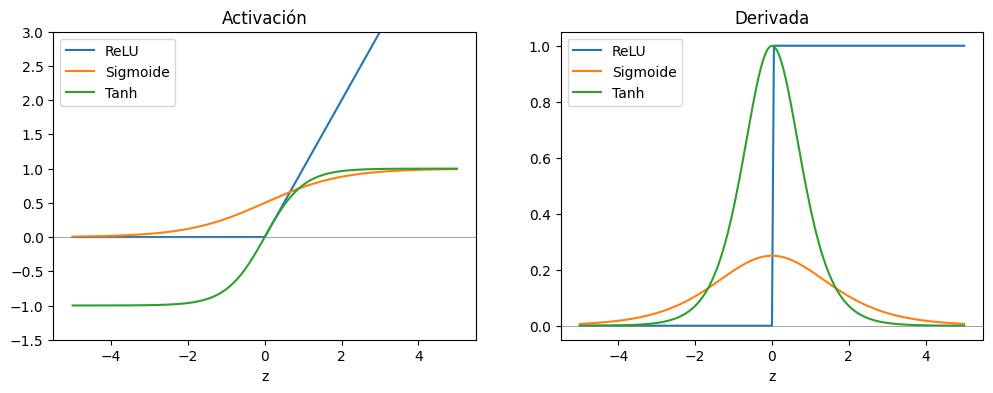

In [8]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))

for nombre, valor, derivada in [("ReLU", relu_a_mano, relu_derivada),
                                ("Sigmoide", sigmoide_a_mano, sigmoide_derivada),
                                ("Tanh", tanh_a_mano, tanh_derivada)]:
    ejes[0].plot(z, valor, label=nombre)
    ejes[1].plot(z, derivada, label=nombre)

ejes[0].set_ylim(-1.5, 3)
ejes[0].set_title("Activación")
ejes[1].set_title("Derivada")
for eje in ejes:
    eje.set_xlabel("z")
    eje.axhline(0, color="gray", linewidth=0.5)
    eje.legend()
plt.show()

El gráfico de la derecha resume la diferencia práctica. La derivada de la ReLU es 1 en toda la mitad positiva. Las de la sigmoide y la tangente hiperbólica solo son apreciables cerca de cero, y la de la sigmoide además es pequeña en todas partes.

## 8. Gradientes que se desvanecen

Por la regla de la cadena, el gradiente que llega a las primeras capas de una red es un producto con un factor $\phi'(z)$ por cada activación que atraviesa. Si la activación es la sigmoide, cada factor es a lo más $1/4$. Después de $L$ capas, el aporte de las activaciones es un factor menor o igual que $(1/4)^L$. (Los pesos de cada capa también entran en el producto; aquí los dejamos fuera para aislar el efecto de la activación.)

Con 10 capas, $(1/4)^{10} \approx 10^{-6}$. Las primeras capas reciben gradientes un millón de veces menores que las últimas y prácticamente no aprenden. Este es el problema del **gradiente que se desvanece**, y es la razón por la que las redes profundas usan ReLU en las capas ocultas.

Lo medimos encadenando 10 activaciones, sin pesos de por medio:

In [9]:
def gradiente_tras_capas(activacion, capas=10):
    x = torch.tensor(0.5, requires_grad=True)
    h = x
    for _ in range(capas):
        h = activacion(h)
    h.backward()
    return x.grad.item()


print(f"10 sigmoides encadenadas: gradiente = {gradiente_tras_capas(torch.sigmoid):.3e}   (cota (1/4)^10 = {0.25 ** 10:.3e})")
print(f"10 tanh encadenadas     : gradiente = {gradiente_tras_capas(torch.tanh):.3e}")
print(f"10 ReLU encadenadas     : gradiente = {gradiente_tras_capas(torch.relu):.3e}")

10 sigmoides encadenadas: gradiente = 3.483e-07   (cota (1/4)^10 = 9.537e-07)
10 tanh encadenadas     : gradiente = 2.228e-01
10 ReLU encadenadas     : gradiente = 1.000e+00


## 9. `Softmax`

La sigmoide convierte un número en una probabilidad. `Softmax` hace lo mismo con un vector: convierte $C$ números cualesquiera (los **logits**) en $C$ probabilidades, una por clase.

$$p_i = \text{softmax}(z)_i = \frac{e^{z_i}}{\sum_{j=1}^{C} e^{z_j}}$$

La exponencial vuelve positivos todos los valores y la división hace que sumen 1. Como la exponencial crece rápido, el logit más grande se lleva la mayor parte de la probabilidad, de ahí el nombre: una versión suave de "quedarse con el máximo".

**Invariancia ante desplazamientos.** Sumar la misma constante $c$ a todos los logits no cambia el resultado, porque el factor $e^c$ aparece arriba y abajo y se cancela:

$$\text{softmax}(z + c)_i = \frac{e^{z_i} e^{c}}{\sum_j e^{z_j} e^{c}} = \text{softmax}(z)_i$$

Solo importan las diferencias entre logits. Esta propiedad se usa en la sección siguiente.

In [10]:
logits = torch.tensor([2.0, 1.0, 0.1])

p_a_mano = torch.exp(logits) / torch.exp(logits).sum()
p = torch.softmax(logits, dim=0)

print("softmax a mano:", p_a_mano)
print("¿coincide con torch.softmax?", torch.allclose(p_a_mano, p))
print("suma de las probabilidades :", p.sum().item())
print("¿softmax(z + 100) = softmax(z)?", torch.allclose(torch.softmax(logits + 100, dim=0), p))

softmax a mano: tensor([0.6590, 0.2424, 0.0986])
¿coincide con torch.softmax? True
suma de las probabilidades : 1.0
¿softmax(z + 100) = softmax(z)? True


**Jacobiano.** A diferencia de las activaciones anteriores, softmax no actúa elemento a elemento: cada salida depende de todas las entradas, porque comparten el denominador. Su derivada es una matriz. Llamando $S = \sum_j e^{z_j}$ y derivando el cociente $p_i = e^{z_i} / S$:

- Si $i = j$: $\quad \dfrac{\partial p_i}{\partial z_i} = \dfrac{e^{z_i} S - e^{z_i} e^{z_i}}{S^2} = p_i - p_i^2 = p_i (1 - p_i)$

- Si $i \ne j$: $\quad \dfrac{\partial p_i}{\partial z_j} = \dfrac{0 - e^{z_i} e^{z_j}}{S^2} = -p_i \, p_j$

Las dos se resumen en una fórmula, con $\delta_{ij}$ igual a 1 si $i = j$ y 0 si no:

$$\frac{\partial p_i}{\partial z_j} = p_i (\delta_{ij} - p_j) \qquad\Longleftrightarrow\qquad J = \text{diag}(p) - p \, p^\top$$

Subir un logit aumenta su propia probabilidad (diagonal positiva) y baja todas las demás (resto negativo). Con dos clases y uno de los logits fijo en 0, el elemento de la diagonal se reduce a $\sigma (1 - \sigma)$, la derivada de la sigmoide.

In [11]:
J = jacobian(lambda v: torch.softmax(v, dim=0), logits)
J_formula = torch.diag(p) - torch.outer(p, p)

print("Jacobiano de softmax:\n", J)
print("¿coincide con diag(p) - p pᵀ?", torch.allclose(J, J_formula))
print("suma de cada columna:", J.sum(dim=0))

Jacobiano de softmax:
 tensor([[ 0.2247, -0.1598, -0.0650],
        [-0.1598,  0.1837, -0.0239],
        [-0.0650, -0.0239,  0.0889]])
¿coincide con diag(p) - p pᵀ? True
suma de cada columna: tensor([0., 0., 0.])


Cada columna suma cero (salvo redondeo): al mover un logit, lo que gana una probabilidad lo pierden las otras, porque el total tiene que seguir siendo 1.

## 10. Estabilidad numérica: `logsumexp` y `log_softmax`

La fórmula de softmax es correcta en el papel y peligrosa en el computador. La exponencial desborda con facilidad: $e^{710}$ ya no cabe en un `float64`, y en `float32` el límite es cerca de $e^{89}$.

In [12]:
logits_grandes = torch.tensor([1000.0, 999.0, 998.0])

ingenuo = torch.exp(logits_grandes) / torch.exp(logits_grandes).sum()
print("exp(1000)        :", torch.exp(logits_grandes[0]).item())
print("fórmula directa  :", ingenuo)
print("torch.softmax    :", torch.softmax(logits_grandes, dim=0))

exp(1000)        : inf
fórmula directa  : tensor([nan, nan, nan])
torch.softmax    : tensor([0.6652, 0.2447, 0.0900])


La fórmula directa calcula $\infty / \infty$ y devuelve `nan`. `torch.softmax` responde bien porque usa la invariancia ante desplazamientos: antes de exponenciar **resta el máximo** a todos los logits. El resultado matemático es idéntico, pero ahora el mayor exponente es 0 y nada desborda.

In [13]:
desplazados = logits_grandes - logits_grandes.max()         # el mayor pasa a ser 0
estable = torch.exp(desplazados) / torch.exp(desplazados).sum()

print("logits desplazados:", desplazados)
print("softmax estable   :", estable)
print("¿coincide con torch.softmax?", torch.allclose(estable, torch.softmax(logits_grandes, dim=0)))

logits desplazados: tensor([ 0., -1., -2.])
softmax estable   : tensor([0.6652, 0.2447, 0.0900])
¿coincide con torch.softmax? True


Las funciones de pérdida necesitan el **logaritmo** de las probabilidades. Calcular primero softmax y después el logaritmo pierde precisión cuando alguna probabilidad es casi cero. Es mejor simplificar antes:

$$\log p_i = \log \frac{e^{z_i}}{\sum_j e^{z_j}} = z_i - \log \sum_j e^{z_j}$$

El segundo término es la función **`logsumexp`**, que se calcula de forma estable con el mismo truco de sacar el máximo $m = \max_j z_j$ fuera:

$$\log \sum_j e^{z_j} = m + \log \sum_j e^{z_j - m}$$

`torch.log_softmax` y `torch.logsumexp` implementan exactamente esto.

In [14]:
m = logits_grandes.max()
logsumexp_a_mano = m + torch.log(torch.exp(logits_grandes - m).sum())
log_softmax_a_mano = logits_grandes - logsumexp_a_mano

print("logsumexp a mano  :", logsumexp_a_mano.item(), "  torch.logsumexp:", torch.logsumexp(logits_grandes, dim=0).item())
print("log_softmax a mano:", log_softmax_a_mano)
print("¿coincide con torch.log_softmax?", torch.allclose(log_softmax_a_mano, torch.log_softmax(logits_grandes, dim=0)))
print("log(softmax) con la fórmula directa:", torch.log(ingenuo))

logsumexp a mano  : 1000.4076059644444   torch.logsumexp: 1000.4076059644444
log_softmax a mano: tensor([-0.4076, -1.4076, -2.4076])
¿coincide con torch.log_softmax? True
log(softmax) con la fórmula directa: tensor([nan, nan, nan])


La regla práctica que sale de aquí: **no apliques `softmax` (ni `sigmoid`) al final del modelo si después viene una función de pérdida que trabaja con logits**. Deja que el modelo entregue logits y que la pérdida haga el cálculo combinado y estable. El notebook siguiente lo muestra con `CrossEntropyLoss` y `BCEWithLogitsLoss`.

## 11. Resumen

| Función | Fórmula | Derivada | Rango |
|---|---|---|---|
| `nn.Linear` | $X W^\top + b$ | $\partial L / \partial W = \delta^\top X$ | todo $\mathbb{R}$ |
| `ReLU` | $\max(0, z)$ | 1 si $z > 0$, 0 si no | $[0, \infty)$ |
| `Sigmoid` | $1 / (1 + e^{-z})$ | $\sigma (1 - \sigma)$, máximo $1/4$ | $(0, 1)$ |
| `Tanh` | $(e^z - e^{-z}) / (e^z + e^{-z})$ | $1 - \tanh^2$, máximo 1 | $(-1, 1)$ |
| `Softmax` | $e^{z_i} / \sum_j e^{z_j}$ | $\text{diag}(p) - p p^\top$ | $(0, 1)$, suma 1 |

- `nn.Linear` inicializa con $\mathcal{U}(-1/\sqrt{n}, 1/\sqrt{n})$. Dividir por $\sqrt{n}$ evita que las activaciones crezcan con el ancho de la capa.
- Con ReLU, mantener la magnitud de las activaciones a través de las capas requiere $\text{Var}(w) = 2/n$ (inicialización de He).
- La derivada de la sigmoide nunca supera $1/4$, lo que desvanece el gradiente en redes profundas.
- Softmax solo depende de las diferencias entre logits. Esa propiedad permite calcularla sin desbordes.
- $\log \text{softmax}(z)_i = z_i - \text{logsumexp}(z)$.

## Ejercicios

1. Crea una `nn.Linear(4, 3)` y calcula a mano la salida de un solo ejemplo usando un `for` sobre las neuronas (producto punto de cada fila con la entrada, más el sesgo). Compara con la capa.
2. En la sección 3, repite el experimento con `nn.init.normal_(w, std=1.0)`. ¿Qué factor por capa predice la teoría? ¿Qué pasa con las magnitudes?
3. Deduce el factor por capa para una pila de capas **sin activación** e indica qué varianza de los pesos mantiene constante la magnitud. Esa es la inicialización de Xavier o Glorot, en su versión que solo considera `fan_in`.
4. `LeakyReLU` se define como $z$ si $z > 0$ y $\alpha z$ si no, con $\alpha = 0.01$ por omisión. Impleméntala a mano con su derivada y compara con `nn.functional.leaky_relu`.
5. Comprueba numéricamente que `torch.softmax` de un vector de dos logits $(0, z)$ entrega $(1 - \sigma(z), \sigma(z))$.
6. La *temperatura* $T$ modifica softmax como $\text{softmax}(z / T)$. Grafica las probabilidades de `logits = [2.0, 1.0, 0.1]` para $T$ entre 0.1 y 10. ¿A qué tiende la distribución en cada extremo?